In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import os

#below checks where python is running from
# print("Current working directory:")
# print(os.getcwd())

#export data from csv to pandas
df_train = pd.read_csv ("../data/raw/imdb_train.csv")
df_test = pd.read_csv ("../data/raw/imdb_test.csv")


print ("Train shape:", df_train.shape)
print ("Test shape:", df_test.shape)

df_train.head()

Train shape: (25000, 3)
Test shape: (25000, 3)


,text,label,sentiment
0,I rented I AM CURIOUS-YELLOW from my video sto...,0,negative
1,"""I Am Curious: Yellow"" is a risible and preten...",0,negative
2,If only to avoid making this type of film in t...,0,negative
3,This film was probably inspired by Godard's Ma...,0,negative
4,"Oh, brother...after hearing about this ridicul...",0,negative


In [3]:
#step B

#q1
#class balannce = counts the number of positives and negatives in the sentiment column. why? below
# This matters because if the dataset is unbalanced, accuracy can be misleading. ex: If 95% of reviews are positive a model could always guess "positive" and still get 95% accuracy. So before training a model, we check the label distribution.+
train_balance = df_train["sentiment"].value_counts()
test_balance = df_test["sentiment"].value_counts()

print ("Train balance: ", train_balance)
print ("\nTest_balance: ", test_balance)





Train balance:  sentiment
negative    12500
positive    12500
Name: count, dtype: int64

Test_balance:  sentiment
negative    12500
positive    12500
Name: count, dtype: int64


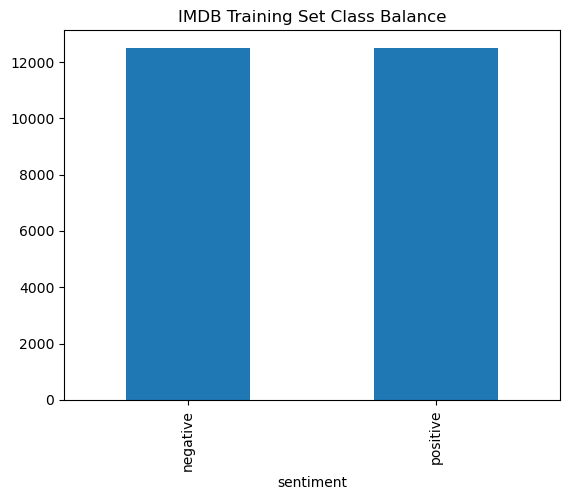

In [4]:
#q1 - Plot the class balance
train_balance.plot(kind="bar")
plt.title("IMDB Training Set Class Balance")
plt.show()


<Axes: >

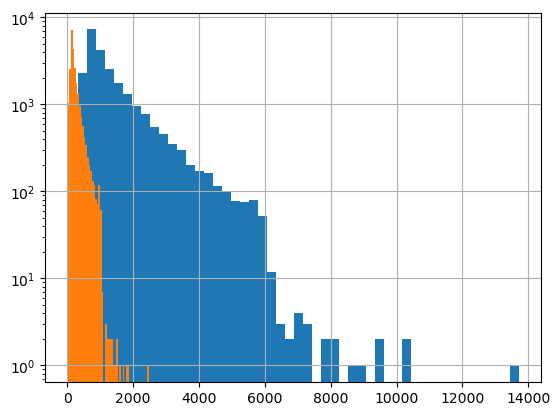

In [ ]:
#q2 -length distribution
df_train["char_length"] = df_train["text"].str.len() #counts number of chars 
df_train ["word_length"] = df_train["text"].str.split().str.len() #splits and then counts number of words in list

df_train[["text", "char_length", "word_length"]].head()



In [6]:
#Summary statistics
df_train[["text", "char_length", "word_length"]].describe()

,char_length,word_length
count,25000.00000,25000.000000
mean,1325.06964,233.787200
std,1003.13367,173.733032
min,52.00000,10.000000
25%,702.00000,127.000000
50%,979.00000,174.000000
75%,1614.00000,284.000000
max,13704.00000,2470.000000


<Axes: >

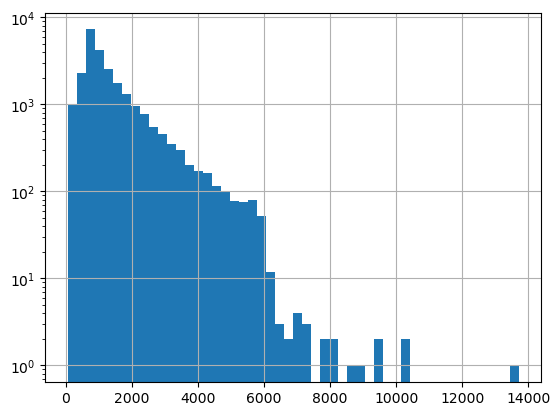

In [7]:
#Character length histogram
df_train["char_length"].hist(bins=50, log=True) #split reviews into 50 buckets 


<Axes: >

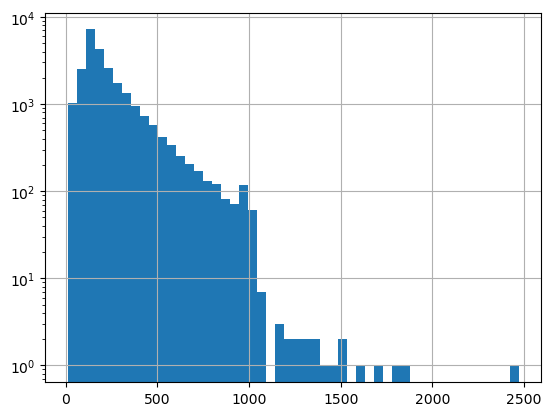

In [8]:
#word length histogram
df_train["word_length"].hist(bins=50, log=True)

In [ ]:
import re
import string
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def simple_clean(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text) ##search text for anything matching this pattern, and replace it with space. . means: any character,  * means: zero or more times,  ? makes it lazy, meaning: stop as soon as possible
    text = text.translate (str.maketrans("", "", string.punctuation))  #delete all punctation
    tokens = text.split()
    tokens = [token for token in tokens if token.isalpha() and token not in ENGLISH_STOP_WORDS]

    return tokens





['movie', 'terrible', 'hated', 'acting']


In [ ]:
#Count top words for one sentiment negative
negative_reviews = df_train[df_train["sentiment"] == "negative"] #this creates a filter, is this row negative? if true keep it if no ignore it
negative_reviews.head()

,text,label,sentiment,char_length,word_length
0,I rented I AM CURIOUS-YELLOW from my video sto...,0,negative,1640,288
1,"""I Am Curious: Yellow"" is a risible and preten...",0,negative,1294,214
2,If only to avoid making this type of film in t...,0,negative,528,93
3,This film was probably inspired by Godard's Ma...,0,negative,706,118
4,"Oh, brother...after hearing about this ridicul...",0,negative,1814,311


In [ ]:
#Collect words from negative reviews
all_negative_words = []

for review in negative_reviews["text"]:
    tokens = simple_clean (review)
    all_negative_words.extend (tokens) #extend adds eahc item indivdually into all_negative_words
print (len (all_negative_words))

#extract the top 20 words in the negative reviews

negative_word_counts = Counter (all_negative_words) #Counter counts how many times each word appears
top_negative_words = negative_word_counts.most_common (20)
print (top_negative_words)

1308108
[('movie', 24179), ('film', 18286), ('like', 10928), ('just', 10537), ('good', 7232), ('bad', 7209), ('really', 6231), ('time', 5954), ('dont', 5169), ('story', 5071), ('people', 4685), ('make', 4554), ('movies', 4202), ('plot', 4023), ('acting', 3978), ('way', 3898), ('characters', 3741), ('think', 3626), ('films', 3518), ('watch', 3510)]


In [14]:
#count top words for positive sentiment

positive_reviews = df_train[df_train["sentiment"] == "positive"]
positive_review_words = []
for review in positive_reviews["text"]:
    tokens = simple_clean (review)
    positive_review_words.extend (tokens)
print (len(positive_review_words))

positive_word_count = Counter (positive_review_words)
top_positive_words = positive_word_count.most_common (20)

print (top_positive_words)

1360308
[('film', 19969), ('movie', 18488), ('like', 8750), ('good', 7478), ('just', 7096), ('story', 6603), ('great', 6333), ('time', 6171), ('really', 5462), ('people', 4354), ('films', 4326), ('best', 4255), ('love', 4194), ('way', 3972), ('life', 3907), ('movies', 3720), ('characters', 3661), ('think', 3632), ('seen', 3390), ('watch', 3371)]


In [ ]:
#Create top bigrams function

def get_top_bigrams (df, sentiment_label, top_n=20):
    subset = df[df["sentiment"] == sentiment_label] #extract either positive or negative

    all_bigrams = []

    for review in subset["text"]:
        tokens = simple_clean (review)

        bigrams = list(zip(tokens, tokens[1:])) #zip() pairs matching positions and stops at the shorter list. ex. below
        #tokens      = ["movie",  "really", "bad"]
        # tokens[1:]  = ["really", "bad",    "acting"]

        all_bigrams.extend(bigrams)
    bigram_counts = Counter (all_bigrams)
    return bigram_counts.most_common (top_n)


In [17]:
#Get top bigrams for both classes
top_negative_bigrams = get_top_bigrams (df_train, "negative", 20)
top_positive_bigrams = get_top_bigrams (df_train, "positive", 20)

print("Top 20 negative bigrams:")
print(top_negative_bigrams)

print("\nTop 20 positive bigrams:")
print(top_positive_bigrams)

Top 20 negative bigrams:
[(('ive', 'seen'), 984), (('waste', 'time'), 733), (('special', 'effects'), 661), (('looks', 'like'), 635), (('dont', 'know'), 623), (('movie', 'just'), 520), (('im', 'sure'), 453), (('look', 'like'), 437), (('bad', 'movie'), 435), (('low', 'budget'), 404), (('dont', 'think'), 384), (('watch', 'movie'), 376), (('worst', 'movie'), 376), (('good', 'movie'), 353), (('really', 'bad'), 352), (('bad', 'acting'), 346), (('movie', 'like'), 327), (('watching', 'movie'), 327), (('main', 'character'), 325), (('year', 'old'), 317)]

Top 20 positive bigrams:
[(('ive', 'seen'), 769), (('new', 'york'), 465), (('dont', 'know'), 462), (('special', 'effects'), 409), (('years', 'ago'), 375), (('good', 'movie'), 347), (('great', 'movie'), 338), (('im', 'sure'), 311), (('real', 'life'), 301), (('pretty', 'good'), 299), (('watch', 'movie'), 293), (('dont', 'think'), 293), (('saw', 'movie'), 285), (('years', 'later'), 281), (('really', 'good'), 275), (('great', 'film'), 271), (('good

In [18]:
#Count duplicate reviews

##This checks each row and asks: Have I seen this exact review text before? and marks them as T or F and sum counts # of T
train_duplicates = df_train.duplicated(subset=["text"]).sum()  
test_duplicates = df_test.duplicated(subset=["text"]).sum()

print("Duplicate reviews in train:", train_duplicates)
print("Duplicate reviews in test:", test_duplicates)

Duplicate reviews in train: 96
Duplicate reviews in test: 199


In [19]:
#Remove duplicate reviews
#.copy() makes a clean independent copy of the result

#drop_duplicates actually removes the duplicate rows. It keeps the first time each review appears and removes later repeats
#subset=["text"] means: Only use the text column to decide if something is duplicated. So two rows are considered duplicates if the review text is exactly the same.
df_train_clean = df_train.drop_duplicates (subset=["text"]).copy()
df_test_clean = df_test.drop_duplicates (subset=["text"]).copy()

print("Train before:", df_train.shape)
print("Train after removing duplicates:", df_train_clean.shape)

print("\nTest before:", df_test.shape)
print("Test after removing duplicates:", df_test_clean.shape)


Train before: (25000, 5)
Train after removing duplicates: (24904, 5)

Test before: (25000, 3)
Test after removing duplicates: (24801, 3)


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer #turns raw text into numbers
from sklearn.linear_model import LogisticRegression #is the classifier that learns positive vs negative
from sklearn.pipeline import Pipeline #connects text-to-numbers and classifier into one workflow
from sklearn.metrics import accuracy_score, f1_score, classification_report

X_train = df_train_clean["text"]
Y_train = df_train_clean ["label"]

X_test = df_test_clean["text"]
y_test = df_test_clean["label"]

#this builds the machine
#TF-IDF learns vocabulary from training reviews
# Logistic Regression learns which words/phrases point to 0 or 1
pipe = Pipeline([("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95
    )),
    ("clf", LogisticRegression(
        max_iter=1000,
        n_jobs=-1
    )),
])

pipe.fit(X_train, Y_train) #actually trains the model

# how pipe.fit works:

# Pipeline receives raw text and labels.

# TF-IDF step:
# 1. Scan all training reviews.
# 2. Build vocabulary of words/bigrams.
# 3. Remove terms based on min_df and max_df.
# 4. Compute IDF weights.
# 5. Convert every review into a sparse numeric vector.

# Logistic Regression step:
# 6. Receive the numeric matrix.
# 7. Start with random/initial weights.
# 8. Adjust weights to reduce classification errors.
# 9. Repeat until it converges or reaches max_iter.
# 10. Store the learned weights.

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.95, min_df=2, ngram_range=(1, 2))),
                ('clf', LogisticRegression(max_iter=1000, n_jobs=-1))])

In [ ]:
#Take the trained pipeline and ask it to predict labels for the test reviews
#y_test = real correct answers
#y_predict = predicted answers by the model
y_pred = pipe.predict(X_test) 

#how accurate/correct is our model. ex. how many correct predictions
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred) #another classsifcation performance measure that combines two ideas: precision = when the model predicts positive, how often is it right? recall = out of all real positives, how many did it find? F1 combines them into one number

print("Accuracy:", accuracy)
print("F1 score:", f1)

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["negative", "positive"]))

Accuracy: 0.890206040079029
F1 score: 0.8912322748152587

Classification report:
              precision    recall  f1-score   support

    negative       0.89      0.88      0.89     12361
    positive       0.89      0.90      0.89     12440

    accuracy                           0.89     24801
   macro avg       0.89      0.89      0.89     24801
weighted avg       0.89      0.89      0.89     24801



In [32]:
#save trained model
import joblib #library to save models
import os
#print (os.getcwd())

os.makedirs ("model", exist_ok=True) #if folders exists dont crash
joblib.dump (pipe, "model/day02_baseline.joblib")
print("Saved model to model/day02_baseline.joblib")



Saved model to model/day02_baseline.joblib
